# Activation functions and dropout

In `cross_analysis.ipynb` we tuned the MLP's learning rate and hidden size and tried a two-layer MLP. Here we vary the two other hyperparameters mentioned in the project description, one at a time, starting from that tuned one-layer MLP:

- the activation function of the hidden layer: ReLU (as in the tutorial, our baseline), tanh, sigmoid, GELU, and the identity (no non-linearity). With the identity the MLP is a linear model, because two linear layers after each other are again one linear map. This tests whether the non-linearity adds anything compared to a log-linear model.
- the dropout rate on the hidden layer: 0, 0.1, 0.3 (baseline), 0.5 and 0.7.

We use NLTK tokens with bag of words (indicators behave the same) and with averaged GloVe (dense inputs, where the activation might matter differently). The rest of the setup is the tuned one-layer MLP from `cross_analysis.ipynb`: learning rate and hidden size chosen on an inner slice, weight decay 0.01, at most 10 epochs with early stopping on the inner slice. Every variant is cross-validated on the parent folds with 3 seeds and 5 folds, the same folds as in the other notebooks, so all scores are paired. Each variant is compared with the baseline with the Bayesian correlated t-test and a ROPE of 0.005 (see section 2 of `cross_analysis.ipynb`). The validation accuracies are only reported; we did not choose anything on them.

Results are cached in `results/` in files starting with `ah_`.

In [1]:
SEEDS = [0, 1, 2]
K = 5
ROPE = 0.005
TOK = "nltk"
FEATURES = ["bow", "glove"]
ACTIVATIONS = ["relu", "tanh", "sigmoid", "gelu", "identity"]   # relu is the baseline
DROPOUTS = [0.0, 0.1, 0.3, 0.5, 0.7]                            # 0.3 is the baseline
RECOMPUTE = False

In [2]:
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv_helpers as cv
from from_tutorial import analysis
from tokenized_data import load

splits, tokenizer = load(TOK)
train, validation = splits["train"], splits["validation"]
y, y_val = train.label.to_numpy(), validation.label.to_numpy()
raw_text = load("bpe_500")[0]["train"].text.tolist()

X, X_val, SCALE = {}, {}, {}
for f in FEATURES:
    X[f], SCALE[f] = cv.build_features(train, tokenizer, f)
    X_val[f], _ = cv.build_features(validation, tokenizer, f)
FOLDS = {seed: cv.parent_folds(raw_text, y, K, seed) for seed in SEEDS}

## Baseline settings (tuned MLP from `cross_analysis.ipynb`)

In [3]:
tuning = pd.DataFrame(json.loads((cv.RESULTS_DIR / "xa_mlp_tuning.json").read_text()).values())
best = tuning[tuning.layers == 1].loc[lambda d: d.groupby("features")["inner-slice accuracy"].idxmax()].set_index("features")
COMMON = dict(dropout=0.3, batch_size=64, weight_decay=1e-2, num_epochs=10, patience=2)
BASE = {f: dict(COMMON, learning_rate=float(best.loc[f, "learning_rate"]), hidden_dim=int(best.loc[f, "hidden_dim"]), layers=1)
        for f in FEATURES}
pd.DataFrame(BASE).T

,dropout,batch_size,weight_decay,num_epochs,patience,learning_rate,hidden_dim,layers
bow,0.3,64.0,0.01,10.0,2.0,0.001,128.0,1.0
glove,0.3,64.0,0.01,10.0,2.0,0.001,32.0,1.0


In [4]:
def run(f, args, tag):
    # cross-validation scores [seeds, folds] and the chosen epochs of one MLP variant; cached in results/
    name = f"ah_mlp_{tag}_{f}_{TOK}_parents"
    if not RECOMPUTE and tag == "baseline":   # identical to cross_analysis.ipynb's tuned MLP: reuse it
        path = cv.RESULTS_DIR / f"xa_mlp_tuned_{f}_{TOK}_parents.json"
        if path.exists() and json.loads(path.read_text()).get("mlp_args") == json.loads(json.dumps(args)):
            return cv.load_results(path.stem), None
    path = cv.RESULTS_DIR / f"{name}.json"
    info = dict(tokenizer=TOK, model="mlp", features=f, seeds=SEEDS, k=K, cv="parents", mlp_args=args)
    acc = None if RECOMPUTE else cv.cached_results(name, require=["chosen_epochs"], **info)
    if acc is not None:
        return acc, json.loads(path.read_text())["chosen_epochs"]
    epochs = []
    acc = [cv.cv_mlp(X[f], y, FOLDS[s], texts=raw_text, seed=s, scale=SCALE[f], epochs_out=epochs, **args) for s in SEEDS]
    cv.save_results(name, acc, chosen_epochs=epochs, **info)
    return np.asarray(acc), epochs


def validation_accuracy(f, args, tag):
    name = f"ah_mlp_{tag}_{f}_{TOK}_validation"
    info = dict(tokenizer=TOK, model="mlp", features=f, mlp_args=args)
    acc = None if RECOMPUTE else cv.cached_results(name, **info)
    if acc is None:
        acc = [[cv.eval_mlp(X[f], y, X_val[f], y_val, texts=raw_text, seed=0, scale=SCALE[f], **args)]]
        cv.save_results(name, acc, **info)
    return float(np.asarray(acc).item())


def compare(base, other):
    post = analysis.BenavoliCorrelatedT(base.flatten(), other.flatten(), runs=base.shape[0])
    p_base, p_tie, p_other = post.probs(ROPE)
    verdict = ("practically equivalent" if p_tie > 0.9 else "baseline better" if p_base > 0.9
               else "variant better" if p_other > 0.9 else "undecided")
    return {"diff vs baseline": post.mean_diff, "P(baseline better)": p_base, "P(tie)": p_tie,
            "P(variant better)": p_other, "verdict (>0.9)": verdict}


def experiment(knob, values, baseline_value):
    rows, scores = [], {}
    for f in FEATURES:
        base_scores, _ = run(f, BASE[f], "baseline")
        for v in values:
            if v == baseline_value:
                acc, epochs, tag, args = base_scores, None, "baseline", BASE[f]
            else:
                args = dict(BASE[f], **{knob: v})
                tag = f"{knob}={v}"
                acc, epochs = run(f, args, tag)
            scores[(f, v)] = acc
            row = {"features": f, knob: v, "cv mean (15 folds)": acc.mean(), "cv std": acc.std(),
                   "mean chosen epoch": np.mean(epochs) if epochs else np.nan,
                   "validation": validation_accuracy(f, args, tag)}
            if v != baseline_value:
                row.update(compare(base_scores, acc))
            rows.append(row)
    return pd.DataFrame(rows).round(4), scores

## 1. Activation functions

In [5]:
act_table, act_scores = experiment("activation", ACTIVATIONS, "relu")
act_table

,features,activation,cv mean (15 folds),cv std,mean chosen epoch,validation,diff vs baseline,P(baseline better),P(tie),P(variant better),verdict (>0.9)
0,bow,relu,0.8031,0.0136,NaN,0.8154,NaN,NaN,NaN,NaN,NaN
1,bow,tanh,0.7985,0.0143,1.5333,0.8028,-0.0045,0.4529,0.5285,0.0186,undecided
2,bow,sigmoid,0.8060,0.0119,2.6000,0.8222,0.0029,0.0677,0.5919,0.3404,undecided
3,bow,gelu,0.8003,0.0145,1.8667,0.8154,-0.0027,0.2461,0.7377,0.0162,undecided
4,bow,identity,0.7981,0.0129,1.6667,0.8050,-0.0049,0.4929,0.5013,0.0058,undecided
5,glove,relu,0.7903,0.0131,NaN,0.7752,NaN,NaN,NaN,NaN,NaN
6,glove,tanh,0.7855,0.0103,2.0000,0.7683,-0.0047,0.4792,0.4897,0.0311,undecided
7,glove,sigmoid,0.7876,0.0090,2.4667,0.7661,-0.0027,0.3097,0.6357,0.0546,undecided
8,glove,gelu,0.7905,0.0115,3.2667,0.7787,0.0002,0.0128,0.9688,0.0183,practically equivalent
9,glove,identity,0.7847,0.0093,2.8000,0.7706,-0.0056,0.5462,0.4232,0.0306,undecided


## 2. Dropout rate

In [6]:
drop_table, drop_scores = experiment("dropout", DROPOUTS, 0.3)
drop_table

,features,dropout,cv mean (15 folds),cv std,mean chosen epoch,validation,diff vs baseline,P(baseline better),P(tie),P(variant better),verdict (>0.9)
0,bow,0.0,0.8020,0.0124,1.9333,0.8119,-0.0011,0.1070,0.8608,0.0322,undecided
1,bow,0.1,0.8012,0.0151,1.9333,0.8119,-0.0019,0.2269,0.7180,0.0551,undecided
2,bow,0.3,0.8031,0.0136,NaN,0.8154,NaN,NaN,NaN,NaN,NaN
3,bow,0.5,0.8080,0.0116,1.5333,0.8165,0.0049,0.0107,0.4956,0.4937,undecided
4,bow,0.7,0.8108,0.0134,2.3333,0.8360,0.0077,0.0017,0.2291,0.7692,undecided
5,glove,0.0,0.7888,0.0113,3.2667,0.7890,-0.0015,0.2969,0.5392,0.1639,undecided
6,glove,0.1,0.7906,0.0090,2.7333,0.7913,0.0003,0.1033,0.7677,0.1290,undecided
7,glove,0.3,0.7903,0.0131,NaN,0.7752,NaN,NaN,NaN,NaN,NaN
8,glove,0.5,0.7900,0.0123,3.0000,0.7764,-0.0002,0.0772,0.8631,0.0597,undecided
9,glove,0.7,0.7865,0.0114,2.8667,0.7787,-0.0038,0.3674,0.6194,0.0133,undecided


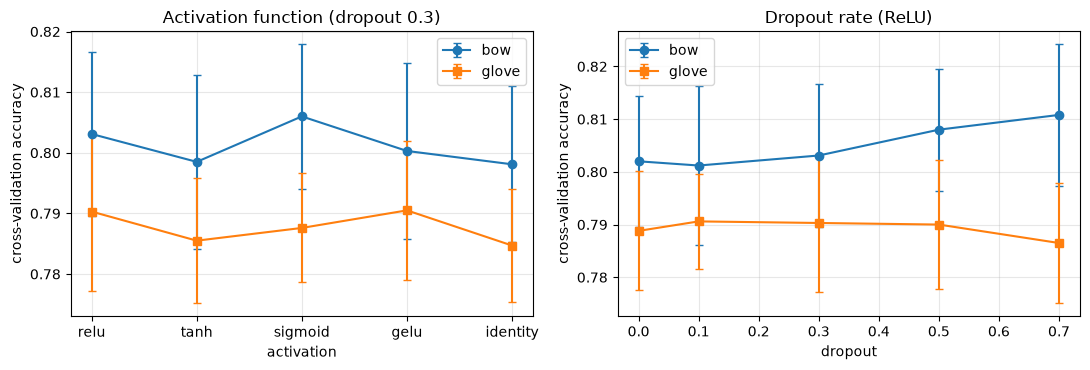

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for f, marker in zip(FEATURES, ["o", "s"]):
    a = act_table[act_table.features == f]
    axes[0].errorbar(a.activation, a["cv mean (15 folds)"], yerr=a["cv std"], marker=marker, capsize=3, label=f)
    d = drop_table[drop_table.features == f]
    axes[1].errorbar(d.dropout, d["cv mean (15 folds)"], yerr=d["cv std"], marker=marker, capsize=3, label=f)
axes[0].set(title="Activation function (dropout 0.3)", xlabel="activation", ylabel="cross-validation accuracy")
axes[1].set(title="Dropout rate (ReLU)", xlabel="dropout", ylabel="cross-validation accuracy")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

In [8]:
# reference point: the log-linear model on the same folds (from cross_analysis.ipynb)
pd.DataFrame([{"features": f, "log-linear cv mean": cv.load_results(f"xa_loglinear_{f}_{TOK}_parents").mean(),
               "MLP, identity activation": act_table[(act_table.features == f) & (act_table.activation == "identity")]["cv mean (15 folds)"].item(),
               "MLP, ReLU (baseline)": act_table[(act_table.features == f) & (act_table.activation == "relu")]["cv mean (15 folds)"].item()}
              for f in FEATURES]).round(4)

,features,log-linear cv mean,"MLP, identity activation","MLP, ReLU (baseline)"
0,bow,0.8081,0.7981,0.8031
1,glove,0.7867,0.7847,0.7903


## Conclusions

The activation function makes no difference. Tanh, sigmoid, GELU and ReLU are all within 0.5 points of each other, on bag of words and on GloVe, and none of them is decided better or worse than ReLU. GELU on GloVe is practically equivalent to ReLU (P(tie) = 0.97). Sigmoid on bag of words looks best (+0.3 points), but P(better) is only 0.34.

Removing the non-linearity costs about 0.5 points (bag of words 0.798 vs 0.803, GloVe 0.785 vs 0.790), and this difference is undecided as well (P(ReLU better) about 0.5). So the non-linearity adds at most half a point, which fits with `cross_analysis.ipynb`, where the MLP never beats log-linear. The linear MLP is also about 1 point below the log-linear model on bag of words (0.798 vs 0.808), even though both are linear classifiers. That difference must come from how the MLP is trained: it only trains on 90% of each fold, since 10% is used to pick the epoch, and with learning rate 1e-3 it is stopped after 1.5 to 3 epochs on average.

Dropout helps a bit on bag of words. Accuracy goes up with the dropout rate: 0.802 without dropout, 0.803 at 0.3 (baseline), 0.808 at 0.5 and 0.811 at 0.7. With dropout 0.7 the MLP is as good as log-linear (0.808-0.809), the best bag-of-words MLP we have. The gain over the baseline (+0.8 points) is not decided though (P(better) = 0.77), and we did not pick this setting beforehand, so we see it as a trend. A likely explanation is that the MLP with 128 hidden units overfits the sparse features quickly and strong dropout counters that. On GloVe (32 hidden units) dropout makes no difference; all rates are within 0.4 points.

Overall, neither the activation function nor the dropout rate makes the MLP better than log-linear. The errors that remain (negation, contrast, mixed sentences; see section 9 of `cross_analysis.ipynb`) depend on word order, and no hyperparameter of a bag-of-words MLP can change that.

The validation accuracies are only for reference. Dropout 0.7 also scores highest there (0.836), but this is a single split of 872 sentences with a standard error of about 1.3 points.